**Importing libraries**

This cell loads the libraries used in the project: `pandas` for tables (DataFrames), `numpy` for numerical operations, `seaborn` and `matplotlib.pyplot` for charts, `nltk` (Natural Language Toolkit) for text processing, and `re` for working with text patterns. The short names (`pd`, `np`, `sns`, `plt`) are standard aliases.

In [304]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import nltk
import re


**Loading the dataset**

This reads the file `twitter_validation.csv` into a DataFrame called `df`. `header=None` is used because the file has no column names in its first row, and `encoding='ISO-8859-1'` tells pandas how to read the special characters in the text. Writing `df` on the last line displays the table.

In [305]:
data = pd.read_csv('twitter_validation.csv',header = None,encoding = 'ISO-8859-1' )
df = pd.DataFrame(data)
df

,0,1,2,3
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...
...,...,...,...,...
995,4891,GrandTheftAuto(GTA),Irrelevant,â­ï¸ Toronto is the arts and culture capital...
996,4359,CS-GO,Irrelevant,tHIS IS ACTUALLY A GOOD MOVE TOT BRING MORE VI...
997,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
998,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


**Naming the columns**

Since the file had no header, the columns were numbered 0 to 3. This cell gives them meaningful names: `ID` (tweet ID), `Media` (the brand or topic the tweet is about), `Target` (the sentiment label), and `Text` (the tweet). `head(10)` then shows the first 10 rows to check the result.

In [306]:
df.columns = ['ID', 'Media', 'Target', 'Text']
df.head(10)

,ID,Media,Target,Text
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...
5,6273,FIFA,Negative,Hi @EAHelp Iâve had Madeleine McCann in my c...
6,7925,MaddenNFL,Positive,Thank you @EAMaddenNFL!! \n\nNew TE Austin Hoo...
7,11332,TomClancysRainbowSix,Positive,"Rocket League, Sea of Thieves or Rainbow Six: ..."
8,1107,AssassinsCreed,Positive,my ass still knee-deep in Assassins Creed Odys...
9,2069,CallOfDuty,Negative,FIX IT JESUS ! Please FIX IT ! What In the wor...


**Checking the shape**

`shape` shows the number of rows and columns as `(rows, columns)`. This tells us how many tweets are in the dataset.

In [307]:
df.shape

(1000, 4)

**Checking the total size**

`size` gives the total number of values in the table, which is rows multiplied by columns.

In [308]:
df.size

4000

**Viewing the last rows**

`tail()` shows the last 5 rows. Looking at both the start and the end of the data helps confirm that it loaded correctly.

In [309]:
df.tail()

,ID,Media,Target,Text
995,4891,GrandTheftAuto(GTA),Irrelevant,â­ï¸ Toronto is the arts and culture capital...
996,4359,CS-GO,Irrelevant,tHIS IS ACTUALLY A GOOD MOVE TOT BRING MORE VI...
997,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
998,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.
999,6960,johnson&johnson,Neutral,Johnson & Johnson to stop selling talc baby po...


**Checking data types**

`dtypes` lists the data type of each column (for example `int64` for numbers and `object` for text).

In [310]:
df.dtypes

,0
ID,int64
Media,object
Target,object
Text,object


**Summary of the dataset**

`info()` prints a compact summary with the column names, data types, and the count of non-null (non-empty) values in each column.

In [311]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   ID      1000 non-null   int64 
 1   Media   1000 non-null   object
 2   Target  1000 non-null   object
 3   Text    1000 non-null   object
dtypes: int64(1), object(3)
memory usage: 31.4+ KB


**Counting missing values**

`isna().sum()` counts the empty values in each column. This shows whether any cleaning for missing data is needed.

In [312]:
df.isna().sum()

,0
ID,0
Media,0
Target,0
Text,0


**Checking for duplicate rows**

`duplicated().sum()` counts rows that are exact copies of another row. A result of 0 means there are no duplicate rows.

In [313]:
df.duplicated().sum()

np.int64(0)

**Listing the column names**

`columns` displays the names of all columns, which is useful as a reference for later steps.

In [314]:
df.columns

Index(['ID', 'Media', 'Target', 'Text'], dtype='object')

**Counting repeated tweets**

`value_counts()` counts how many times each unique tweet appears in the `Text` column. This helps us check whether the same tweet text is repeated.

In [315]:
Text = df['Text'].value_counts()
Text

,count
Text,
Wow,2
Nvidia Gives Positive Forecasts Despite Coronavirus Hit #Nvidia\n\ncdrinfo.com/d7/content/nviâ¦ https://t.co/utMxGW1CIf,1
This has to be my favourite cinematic in all of World of @Warcraft pic.twitter.com/zlCC1HsQ3l,1
Know Your History...unless it involves China....because like....we have investors and shit...,1
Congratulations to @ninamanning78 on publication day. Hope you have a fabulous day and that your book flies ððð,1
...,...
Nvidia GeForce Now: Google Stadia rival suffers anotherÂ blow news89.net/nvidia-geforceâ¦ https://t.co/9ijNjV7L4C,1
"I SAW A TWEET ABOUT HOW IT'S A STORY TOLD OVER AND OVER CUZ THEY'RE MAD MEN DIED IN THE WAR AND IT DIDN'T HAVE BATTLEFIELD 1 TREATMENT, I CAN'T EVEN THINK OF ANOTHER WW1 MOVIE PPL WOULD EVEN KNOW",1
Bro I had an abusive internet boyfriend that used to call me a stupid bitch whenever niggas used to like my pics on facebook and I used to beg him to not be mad at me. I was such a stupid bitch FOR REAL,1


**Counting tweets per media**

This counts how many tweets belong to each brand or topic in the `Media` column and saves the result in `Media` for plotting.

In [316]:
Media = df['Media'].value_counts()
Media

,count
Media,
RedDeadRedemption(RDR),40
johnson&johnson,39
PlayerUnknownsBattlegrounds(PUBG),38
FIFA,38
LeagueOfLegends,37
ApexLegends,36
Nvidia,35
TomClancysRainbowSix,35
GrandTheftAuto(GTA),35


**Horizontal bar chart of media**

`plt.barh()` draws a horizontal bar chart of the tweet count for each media name, which suits long labels. The remaining lines set the axis labels, font sizes, and the chart title.

Text(0.5, 1.0, 'Media Distribution')

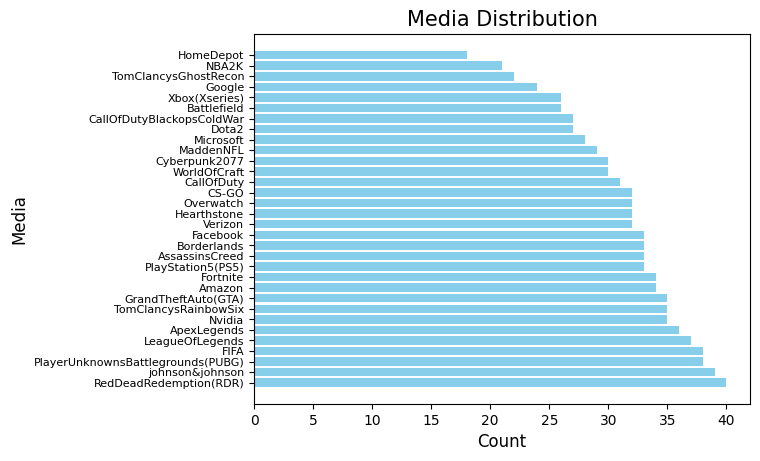

In [317]:
plt.barh(Media.index, Media.values, color='skyblue')

plt.xlabel('Count', fontsize=12)
plt.ylabel('Media', fontsize=12)
plt.yticks(fontsize=8)
plt.xticks(fontsize=10)
plt.title('Media Distribution', fontsize=15)

**Counting the sentiment labels**

This counts how many tweets fall under each `Target` label (Positive, Negative, Neutral, and Irrelevant) and saves the result in `Target`.

In [318]:
Target = df['Target'].value_counts()
Target

,count
Target,
Neutral,285
Positive,277
Negative,266
Irrelevant,172


**Bar chart of the sentiment labels**

A bar chart of the label counts, so we can see how balanced the sentiment classes are.

Text(0.5, 1.0, 'Target Distribution')

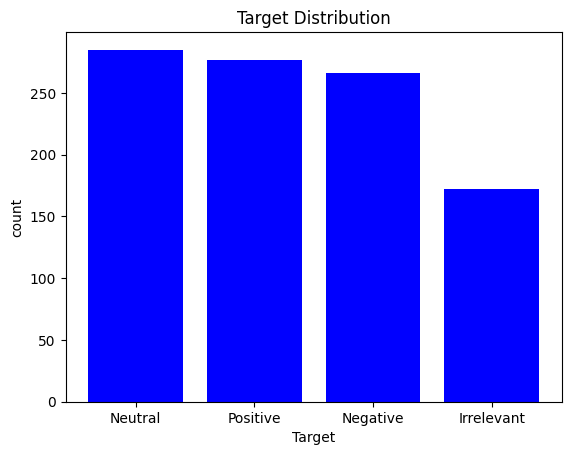

In [319]:
plt.bar(Target.index,Target.values,color = 'b')
plt.xlabel('Target')
plt.ylabel('count')
plt.title('Target Distribution')

**Checking data types again**

Shows the column data types once more before the data is cleaned.

In [320]:
df.dtypes

,0
ID,int64
Media,object
Target,object
Text,object


**Removing "Irrelevant" tweets**

This finds all rows where `Target` is `Irrelevant` and drops them. We only want to classify tweets as Positive, Negative, or Neutral, so the irrelevant ones are removed.

In [321]:
df = df.drop(df[df['Target'] == 'Irrelevant'].index)
df

,ID,Media,Target,Text
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...
5,6273,FIFA,Negative,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...,...,...,...
993,314,Amazon,Negative,Please explain how this is possible! How can t...
994,9701,PlayStation5(PS5),Positive,Good on Sony. As much as I want to see the new...
997,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
998,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


**Resetting the index**

After rows are dropped, the row numbers have gaps. `reset_index(drop=True)` renumbers the rows from 0 and discards the old index.

In [322]:
df = df.reset_index(drop=True)
df

,ID,Media,Target,Text
0,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
2,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,4433,Google,Neutral,Now the President is slapping Americans in the...
4,6273,FIFA,Negative,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...,...,...,...
823,314,Amazon,Negative,Please explain how this is possible! How can t...
824,9701,PlayStation5(PS5),Positive,Good on Sony. As much as I want to see the new...
825,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
826,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


**Dropping unneeded columns**

The `ID` and `Media` columns are not needed for predicting sentiment, so they are removed. `axis=1` means columns, and `inplace=True` applies the change directly to `df`.

In [323]:
df.drop(['ID','Media'],axis = 1,inplace = True)
df

,Target,Text
0,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,Negative,@Microsoft Why do I pay for WORD when it funct...
2,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,Neutral,Now the President is slapping Americans in the...
4,Negative,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...,...
823,Negative,Please explain how this is possible! How can t...
824,Positive,Good on Sony. As much as I want to see the new...
825,Positive,Today sucked so itâs time to drink wine n pl...
826,Positive,Bought a fraction of Microsoft today. Small wins.


**Converting labels to numbers**

Machine learning models work with numbers, so the text labels are converted using `map()`: Positive becomes `1`, Negative becomes `-1`, and Neutral becomes `0`. The lines starting with `#` are comments that describe this mapping.

In [324]:
# target
# positive - 1
# negative - -1
# netural - 0

# map
df['Target'] = df['Target'].map({'Positive': 1,'Negative': -1,'Neutral': 0})




**Viewing the encoded data**

Displays `df` to check that `Target` now contains numbers.

In [325]:
df

,Target,Text
0,0,BBC News - Amazon boss Jeff Bezos rejects clai...
1,-1,@Microsoft Why do I pay for WORD when it funct...
2,-1,"CSGO matchmaking is so full of closet hacking,..."
3,0,Now the President is slapping Americans in the...
4,-1,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...,...
823,-1,Please explain how this is possible! How can t...
824,1,Good on Sony. As much as I want to see the new...
825,1,Today sucked so itâs time to drink wine n pl...
826,1,Bought a fraction of Microsoft today. Small wins.


**Selecting the tweet text**

The `Text` column is stored in a variable called `tweet`. All text cleaning in the next steps is applied to this variable.

In [326]:
tweet = df.Text
tweet


,Text
0,BBC News - Amazon boss Jeff Bezos rejects clai...
1,@Microsoft Why do I pay for WORD when it funct...
2,"CSGO matchmaking is so full of closet hacking,..."
3,Now the President is slapping Americans in the...
4,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...
823,Please explain how this is possible! How can t...
824,Good on Sony. As much as I want to see the new...
825,Today sucked so itâs time to drink wine n pl...
826,Bought a fraction of Microsoft today. Small wins.


**Downloading NLTK resources**

This downloads two NLTK resources: `stopwords` (a list of common words such as "the" and "is") and `punkt_tab` (data used for splitting text into tokens). The output says they are already up to date.

In [327]:
nltk.download('stopwords')
nltk.download('punkt_tab')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

**Tokenization**

`TweetTokenizer` splits each tweet into separate tokens (words and symbols) and is designed to handle tweet features such as mentions and hashtags. The tokens are then joined back into one string with spaces between them.

In [328]:
# Tokenization
from nltk.tokenize import TweetTokenizer
tk = TweetTokenizer()
tweet = tweet.apply(lambda x:tk.tokenize(x)).apply(lambda x:' '.join(x))
tweet

,Text
0,BBC News - Amazon boss Jeff Bezos rejects clai...
1,@Microsoft Why do I pay for WORD when it funct...
2,CSGO matchmaking is so full of closet hacking ...
3,Now the President is slapping Americans in the...
4,Hi @EAHelp Iâ   ve had Madeleine McCann in m...
...,...
823,Please explain how this is possible ! How can ...
824,Good on Sony . As much as I want to see the ne...
825,Today sucked so itâ   s time to drink wine n...
826,Bought a fraction of Microsoft today . Small w...


**Removing special characters**

This replaces every character that is not a letter or a digit (`[^a-zA-Z0-9]`) with a space. It removes punctuation, symbols, and emojis. `regex=True` tells pandas that the pattern is a regular expression.

In [329]:
# remove special characters

tweet = tweet.str.replace('[^a-zA-Z0-9]',' ',regex=True)
tweet

,Text
0,BBC News Amazon boss Jeff Bezos rejects clai...
1,Microsoft Why do I pay for WORD when it funct...
2,CSGO matchmaking is so full of closet hacking ...
3,Now the President is slapping Americans in the...
4,Hi EAHelp I ve had Madeleine McCann in m...
...,...
823,Please explain how this is possible How can ...
824,Good on Sony As much as I want to see the ne...
825,Today sucked so it s time to drink wine n...
826,Bought a fraction of Microsoft today Small w...


**Removing very short words**

Each tweet is tokenized again and only words with 3 or more characters are kept. This removes tiny words and leftover fragments that carry little meaning. The words are then joined back into a string.

In [330]:
# minimum characters
# 3 characters
# removing less that 3 characters
tweet = tweet.apply(lambda x:" ".join([w for w in tk.tokenize(x)if len(w)>=3]))
tweet


,Text
0,BBC News Amazon boss Jeff Bezos rejects claims...
1,Microsoft Why pay for WORD when functions poor...
2,CSGO matchmaking full closet hacking truly awf...
3,Now the President slapping Americans the face ...
4,EAHelp had Madeleine McCann cellar for the pas...
...,...
823,Please explain how this possible How can they ...
824,Good Sony much want see the new PS5 what going...
825,Today sucked time drink wine play borderlands ...
826,Bought fraction Microsoft today Small wins


**Stemming**

Stemming reduces words to their root form, so related words are treated as the same word (for example, "smoking" and "smoked" both become "smok"). `SnowballStemmer('english')` is used, and each word is also converted to lowercase.

In [331]:
# stemming
from nltk.stem import SnowballStemmer
st = SnowballStemmer('english')
tweet= tweet.apply(lambda x:[st.stem(i.lower())for i in tk.tokenize(x)]).apply(lambda x:' '.join(x))
tweet

,Text
0,bbc news amazon boss jeff bezo reject claim co...
1,microsoft whi pay for word when function poor ...
2,csgo matchmak full closet hack truli aw game
3,now the presid slap american the face that rea...
4,eahelp had madelein mccann cellar for the past...
...,...
823,pleas explain how this possibl how can they le...
824,good soni much want see the new ps5 what go ri...
825,today suck time drink wine play borderland unt...
826,bought fraction microsoft today small win


**Removing stopwords**

Stopwords are very common words (such as "the", "and", "for") that add little meaning. This cell loads NLTK's English stopword list and removes those words from each tweet.

In [332]:
# Remove stopwords
from nltk.corpus import stopwords

stop = stopwords.words('english')
tweet = tweet.apply(lambda x:[i for i in tk.tokenize(x) if i not in stop]).apply(lambda x:' '.join(x))
tweet

,Text
0,bbc news amazon boss jeff bezo reject claim co...
1,microsoft whi pay word function poor samsungus...
2,csgo matchmak full closet hack truli aw game
3,presid slap american face realli commit unlaw ...
4,eahelp madelein mccann cellar past year littl ...
...,...
823,pleas explain possibl let compani overcharg sc...
824,good soni much want see new ps5 go right much ...
825,today suck time drink wine play borderland sun...
826,bought fraction microsoft today small win


**Vectorization with TF-IDF**

Models cannot read text, so `TfidfVectorizer` converts each tweet into a list of numbers. TF-IDF gives each word a weight based on how often it appears in a tweet and how rare it is across all tweets. `fit_transform()` learns the vocabulary and creates the matrix, which is stored in `data`. The output shows a sparse matrix (a compact format that stores only non-zero values).

In [333]:
# vectorization
from sklearn.feature_extraction.text import TfidfVectorizer
vec = TfidfVectorizer()
data = vec.fit_transform(tweet)
data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10461 stored elements and shape (828, 3763)>

**Viewing the TF-IDF values**

`print(data)` shows the stored values of the matrix. Each line has the form (tweet number, word number) followed by that word's TF-IDF weight.

In [334]:
print(data)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10461 stored elements and shape (828, 3763)>
  Coords	Values
  (0, 515)	0.49155204783978756
  (0, 2267)	0.38864111655856126
  (0, 353)	0.1515362387424402
  (0, 610)	0.22681557001542715
  (0, 1813)	0.24577602391989378
  (0, 545)	0.2608257828483461
  (0, 2741)	0.2608257828483461
  (0, 785)	0.21432663830218204
  (0, 838)	0.17354914655342313
  (0, 286)	0.22681557001542715
  (0, 1976)	0.13277165480466424
  (0, 1108)	0.23509805002803952
  (0, 982)	0.2608257828483461
  (0, 668)	0.2608257828483461
  (1, 2135)	0.24555654927912696
  (1, 3619)	0.26216072802580975
  (1, 2442)	0.3126902562590763
  (1, 3659)	0.36557591217188057
  (1, 1383)	0.4055823664694651
  (1, 2538)	0.3821800909185634
  (1, 2871)	0.4055823664694651
  (1, 775)	0.4055823664694651
  (2, 934)	0.3041178383627944
  (2, 2085)	0.3963165794888645
  (2, 1380)	0.3790982275064499
  :	:
  (825, 3363)	0.2560582225152133
  (825, 3373)	0.3395996844494918
  (825, 826)	0.25069214907989

**Creating the target array**

The `Target` column is converted to a NumPy array and stored in `y`. These are the sentiment labels (1, 0, -1) that the models will learn to predict.

In [335]:
y = df['Target'].values
y

array([ 0, -1, -1,  0, -1,  1,  1,  1, -1,  1,  1, -1,  0, -1,  1,  1, -1,
        1, -1, -1,  0, -1,  0,  0, -1, -1,  1,  1, -1,  1, -1,  0,  0,  1,
        0,  1,  0,  0,  0,  1,  0, -1, -1, -1,  0,  1, -1, -1,  1,  1,  1,
        1,  1, -1, -1,  1,  1, -1,  0, -1,  0, -1,  1, -1, -1,  1,  1,  1,
        0,  0,  0,  1,  1,  0,  1,  0, -1, -1,  0,  0, -1,  1, -1, -1, -1,
        0,  1,  0, -1,  1,  1,  0,  1,  0,  1, -1,  0,  0,  0, -1,  0, -1,
        0,  0,  1,  1,  0, -1, -1,  1, -1,  0, -1,  1,  0, -1,  0,  1,  0,
        1,  1,  0,  0,  0,  0,  1,  0,  1,  1, -1,  0,  0,  0,  0, -1,  0,
        1, -1,  0, -1,  0, -1, -1, -1,  1,  1,  1,  0,  0,  1,  0,  0,  0,
        1,  0, -1, -1,  0,  1,  1,  0,  1,  1,  0,  0, -1, -1, -1, -1,  1,
        0,  0,  1,  1,  1,  1, -1,  1,  1,  0, -1, -1, -1,  1,  1, -1, -1,
        1,  1, -1,  1,  1, -1,  1,  0, -1,  0,  0,  1, -1,  1,  1,  0,  1,
       -1, -1,  1,  1,  1,  1,  0,  0,  1, -1,  0,  1,  0, -1,  0,  0, -1,
        1,  1, -1,  0,  1

**Splitting into training and testing data**

`train_test_split` divides the data into a training set (80%) and a testing set (20%) using `test_size=0.2`. The models learn from the training set and are then checked on the testing set. `random_state=42` makes the split the same every time the code runs.

In [336]:
# training and testing
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(data, y, test_size=0.2, random_state=42)


**Model 1: K-Nearest Neighbors (KNN)**

This trains a KNN classifier with `n_neighbors=5`, which predicts a tweet's sentiment by looking at the 5 most similar training tweets. The model is trained with `fit()`, makes predictions on the test data, and `accuracy_score` measures the share of correct predictions. The score is saved in `score_knn` and printed.

In [337]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. K-Nearest Neighbors (KNN)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train, y_train)
score_knn = accuracy_score(y_test, knn.predict(x_test))
print(f"KNN Accuracy: {score_knn}")

KNN Accuracy: 0.4759036144578313


**Model 2: Random Forest**

This trains a Random Forest classifier, which combines many decision trees and uses their combined vote. Here it uses `n_estimators=5` (5 trees). The accuracy on the test data is saved in `score_rf` and printed.

In [338]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 2. Random Forest
rf_model = RandomForestClassifier(n_estimators=5, random_state=42)
rf_model.fit(x_train, y_train)
score_rf = accuracy_score(y_test, rf_model.predict(x_test))
print(f"Random Forest Accuracy: {score_rf}")

Random Forest Accuracy: 0.463855421686747


**Model 3: Decision Tree**

This trains a Decision Tree classifier, which makes predictions by following a series of yes/no questions. `criterion='entropy'` chooses how the tree decides where to split. The test accuracy is saved in `score_dt` and printed.

In [339]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 3. Decision Tree
dt_model = DecisionTreeClassifier(random_state=42, criterion='entropy')
dt_model.fit(x_train, y_train)
score_dt = accuracy_score(y_test, dt_model.predict(x_test))
print(f"Decision Tree Accuracy: {score_dt}")

Decision Tree Accuracy: 0.4397590361445783


**Model 4: Naive Bayes**

This trains a Multinomial Naive Bayes classifier, a model based on probabilities that is commonly used for text classification. The test accuracy is saved in `score_nb` and printed.

In [340]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# 4. Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(x_train, y_train)
score_nb = accuracy_score(y_test, nb_model.predict(x_test))
print(f"Naive Bayes Accuracy: {score_nb}")

Naive Bayes Accuracy: 0.5481927710843374


**Comparing model accuracy in a table**

The four accuracy scores are collected into a DataFrame with one row per model. `display()` shows it as a table so the models can be compared easily.

In [341]:
df_accuracy = pd.DataFrame({
    'Model': ['KNN', 'Random Forest', 'Decision Tree', 'Naive Bayes'],
    'Accuracy': [score_knn, score_rf, score_dt, score_nb]
})
display(df_accuracy)

,Model,Accuracy
0,KNN,0.475904
1,Random Forest,0.463855
2,Decision Tree,0.439759
3,Naive Bayes,0.548193


**Bar chart of model comparison**

Draws a bar chart of each model's accuracy. `plt.bar_label()` writes the accuracy value above each bar, and `plt.ylim(0, 1.0)` sets the vertical axis from 0 to 1.

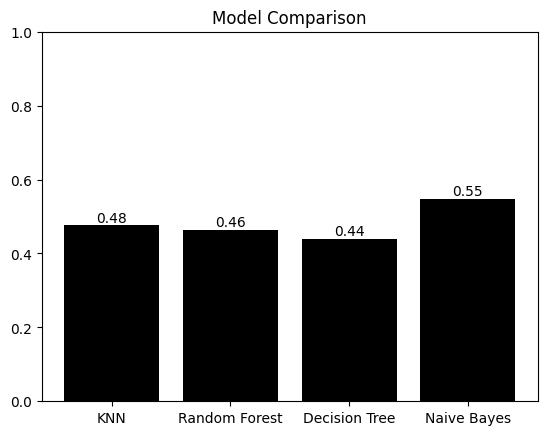

In [342]:
bars = plt.bar(df_accuracy['Model'], df_accuracy['Accuracy'], color='k')
plt.bar_label(bars, fmt='%.2f')
plt.title("Model Comparison")
plt.ylim(0, 1.0)
plt.show()

**Predicting the sentiment of a new review**

This tests the trained model on a new sentence. The text "the movie is good" is converted into numbers using the same TF-IDF vectorizer (`vec.transform`), and the Naive Bayes model predicts its sentiment. The result is then printed as a word: 1 is Positive, 0 is Neutral, and anything else is Negative.

In [350]:
review = ['the movie is good']
data1 = vec.transform(review)
score_nb = nb_model.predict(data1)
score_nb
if score_nb == 1:
  print('Positive')
elif score_nb == 0:
  print('Netural')
else:
  print('Negative')

Positive
